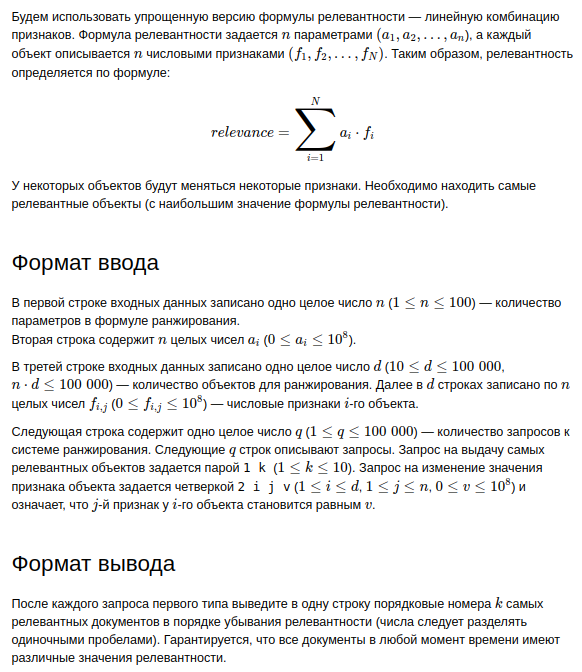
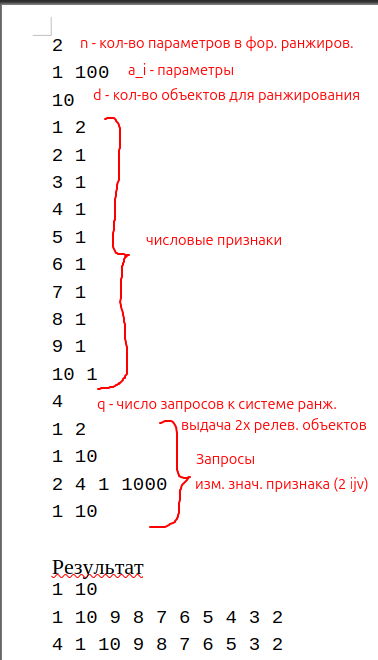

In [ ]:

import heapq


def solve(text):
    data = iter(text.split()) #по строкам
    
    def read_int():
        return int(next(data))

    
    n = read_int() #n - кол-во параметров
    weights = [read_int() for _ in range(n)] #параметры a_i, их n штук
    d = read_int() # d - кол-во объектов для ранжирования
    features = [[read_int() for _ in range(n)] for _ in range(d)]  # признаки объектов f_ij, матрица

    relevance = []
    for obj in range(d): #подумать про поумнее метод
        total = 0
        for j in range(n):
            total += weights[j] * features[obj][j]
        relevance.append(total)

   

    version = [0] * d #длина = кол-ву объектов ранжирования
    heap = [(-relevance[i], i, 0) for i in range(d)] # т к минимум в начале кучи
    heapq.heapify(heap) # сложность?

    q = read_int() #число запросов к системе ранжирования
    answers = []

    for _ in range(q):
        query_type = read_int()

        if query_type == 1: #если вывод самых релевантных
            k = min(read_int(), d)

            top = []
            while len(top) < k:
                entry = heapq.heappop(heap)
                _, obj, ver = entry
                if ver == version[obj]:# запись актуальна
                    top.append(entry)

            answers.append(' '.join(str(obj + 1) for _, obj, _ in top))

            
            for entry in top:
                heapq.heappush(heap, entry)

        else:#если изменение значения
            i = read_int() - 1 #признак
            j = read_int() - 1 #объект
            v = read_int() #значение

            old_value = features[i][j] #чтобы куча не разрасталась одинаковыми значениями
            if v != old_value:
                features[i][j] = v
                relevance[i] += weights[j] * (v - old_value)

                version[i] += 1
                heapq.heappush(heap, (-relevance[i], i, version[i]))

    return '\n'.join(answers)

In [2]:
example = """2
1 100
10
1 2
2 1
3 1
4 1
5 1
6 1
7 1
8 1
9 1
10 1
4
1 2
1 10
2 4 1 1000
1 10"""

expected = """1 10
1 10 9 8 7 6 5 4 3 2
4 1 10 9 8 7 6 5 3 2"""

result = solve(example)
print(result)
assert result == expected

1 10
1 10 9 8 7 6 5 4 3 2
4 1 10 9 8 7 6 5 3 2
